# Next-day temperature forecasting with deep learning

**Course project – Deep Learning, Koźmiński University 2026/27** · dataset option 3 in `Grading.md`

**Task:** take the **last three days** of weather data and predict the **temperature of the next day**. `Apparent Temperature (C)` is never used. Regression.

> **Our decision – which temperature?** The brief doesn't specify, so we predict the next day's **daily mean temperature** (average of its 24 hourly readings, local time).

| Required in the presentation (`Grading.md`) | Where |
|---|---|
| Data exploration and conclusions, and how they shaped the network | §2–3 |
| Feature engineering and why | §4 |
| Network architecture | §7, §9 |
| Framework and methods, and why | §0, §5, §7 |
| Issues and problems in the data | §2 (**Issue** marks), §11 |

**Method.** We follow the course rules: the reproducible-experiment checklist from Class 1 (`tensors.ipynb`), the tabular baseline and tuning order from Class 2, and target scaling, K-fold validation and final retraining from `regression.ipynb`.

**Files.** Everything – cleaning, features, models, the experiment search and the final evaluation – is in this notebook. `config.yaml` holds every setting, including the search plan. Every training run is logged in `runs/experiments.jsonl`.

## 0. Setup

**Framework: Keras 3 on TensorFlow.** It's the framework used in the course. The functional API (Class 3) lets us combine several inputs (hourly series, daily rows, calendar), and `set_random_seed` plus op determinism make runs exactly repeatable.

In [1]:
import os
os.environ["PYTHONHASHSEED"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import hashlib, json, platform, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import keras
import tensorflow as tf

In [2]:
def load_config(path="config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)


def set_seed(seed):
    keras.utils.set_random_seed(seed)               # Python, NumPy, TensorFlow
    tf.config.experimental.enable_op_determinism()


CONFIG = load_config()
RUNS = Path("runs"); RUNS.mkdir(exist_ok=True)
print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| pandas", pd.__version__, "| NumPy", np.__version__)
print("Hardware:", platform.machine(), subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
      capture_output=True, text=True).stdout.strip(), "(CPU training)")
print("Seeds:", CONFIG["seeds"])

Python 3.12.14 | TensorFlow 2.21.0 | Keras 3.15.1 | pandas 3.0.6 | NumPy 2.5.4
Hardware: arm64 Apple M5 Pro (CPU training)
Seeds: [123, 2137, 15190]


## 1. Data and its version

The dataset's SHA-256 hash is stored in `config.yaml` and checked when loading, so we know exactly which version was used.

Source: Kaggle `arnab132/weather-dataset`, version 1, downloaded 2026-10-22. It contains hourly observations from 2006 to 2016.

In [3]:
raw = pd.read_csv(CONFIG["data"]["path"])
print(raw.shape)
raw.head(3)

(96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.


## 2. Cleaning – issues found

`load_clean` reads the file, checks its hash and fixes every data problem we found during exploration. Each fix is explained below.

In [4]:
RENAME = {
    "Temperature (C)": "temp", "Humidity": "humidity", "Wind Speed (km/h)": "wind_speed",
    "Wind Bearing (degrees)": "wind_bearing", "Visibility (km)": "visibility",
    "Pressure (millibars)": "pressure", "Precip Type": "precip_type",
    "Summary": "summary", "Daily Summary": "daily_summary",
}


def load_clean(cfg, verbose=False):
    """Read the CSV, check its hash and fix the data issues found during exploration."""
    path = Path(cfg["data"]["path"])
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == cfg["data"]["sha256"], f"Dataset changed! hash = {sha}"
    df = pd.read_csv(path)
    log = {}
    # Mixed +01:00/+02:00 offsets (daylight saving time): parse as UTC, then convert to local time.
    df["time"] = pd.to_datetime(df["Formatted Date"], utc=True).dt.tz_convert(cfg["data"]["timezone"])
    log["sorted_in_file"] = bool(df["time"].is_monotonic_increasing)
    df = df.sort_values("time")
    log["duplicate_timestamps"] = int(df["time"].duplicated().sum())
    df = df.drop_duplicates(subset="time").set_index("time")
    log["loud_cover_unique"] = df["Loud Cover"].unique().tolist()
    log["pressure_zero_rows"] = int((df["Pressure (millibars)"] == 0).sum())
    log["humidity_zero_rows"] = int((df["Humidity"] == 0).sum())
    for col in ["Pressure (millibars)", "Humidity"]:   # 0 mbar / 0 % humidity = sensor fault
        df[col] = df[col].replace(0, np.nan).interpolate(method="time")
    # The forbidden column is dropped immediately so it can't leak anywhere.
    df = df.drop(columns=["Apparent Temperature (C)", "Loud Cover", "Formatted Date"]).rename(columns=RENAME)
    if verbose:
        for k, v in log.items():
            print(f"{k}: {v}")
    return df

In [5]:
df = load_clean(CONFIG, verbose=True)
print(df.shape, "| from", df.index.min(), "to", df.index.max())

sorted_in_file: False
duplicate_timestamps: 24
loud_cover_unique: [0.0]
pressure_zero_rows: 1288
humidity_zero_rows: 22
(96429, 9) | from 2006-01-01 00:00:00+01:00 to 2016-12-31 23:00:00+01:00


- **Issue 1 – mixed time zones.** Timestamps switch between `+0100` and `+0200` (daylight saving). We parse to UTC and convert to `Europe/Budapest`, so "a day" is a real local calendar day. Local days have 23 or 25 hours at the DST switches. For the hourly model input we use a regular UTC hourly grid instead (§4).
- **Issue 2 – the file is not sorted by time.** Sorting is required before any windowing.
- **Issue 3 – 24 duplicated rows.** The whole of 2010-08-02 appears twice; we drop the duplicates.
- **Issue 4 – `Loud Cover` is always 0**, so it carries no information and is dropped.
- **Issue 5 – 1,288 hours with pressure = 0 mbar** and **22 with humidity = 0**. Both are impossible values, i.e. missing data. We interpolate them in time.
- **Forbidden column:** `Apparent Temperature (C)` is dropped inside `load_clean`, so it can't leak into anything later. Its correlation with temperature is 0.99, so using it would be close to cheating.

## 3. Exploration

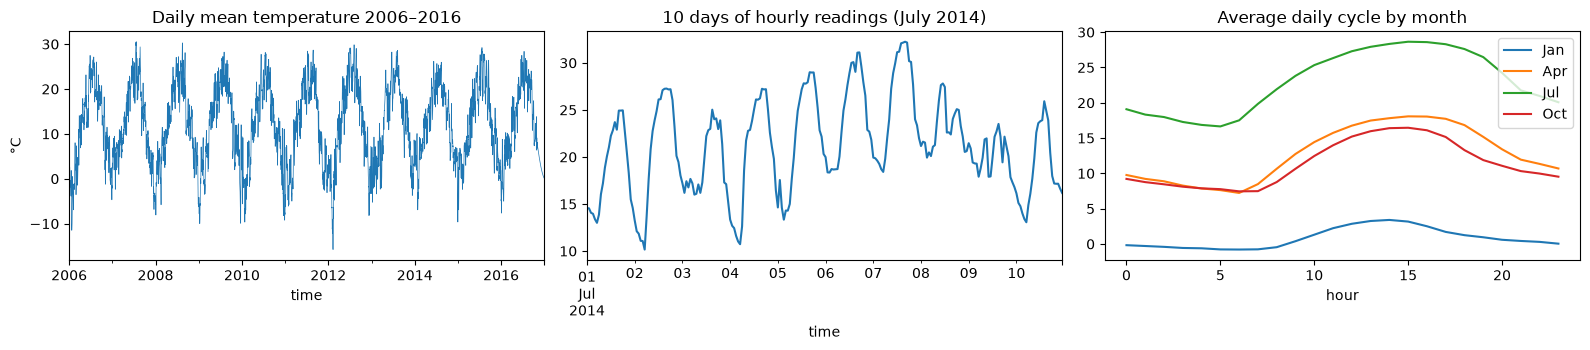

In [6]:
daily_temp = df["temp"].resample("D").mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
daily_temp.plot(ax=ax[0], lw=0.5); ax[0].set_title("Daily mean temperature 2006–2016"); ax[0].set_ylabel("°C")
df["temp"].loc["2014-07-01":"2014-07-10"].plot(ax=ax[1]); ax[1].set_title("10 days of hourly readings (July 2014)")
by_hour = df.groupby([df.index.month, df.index.hour])["temp"].mean().unstack(0)
by_hour[[1, 4, 7, 10]].plot(ax=ax[2]); ax[2].set_title("Average daily cycle by month"); ax[2].set_xlabel("hour")
ax[2].legend(["Jan", "Apr", "Jul", "Oct"])
plt.tight_layout(); plt.show()

**Conclusions**
- **Yearly cycle** (about 25 °C between winter and summer). It's fully predictable from the calendar, so the model gets the day of the year of the predicted day as a feature. This isn't leakage: the date is always known in advance.
- **Daily cycle** (about 5–12 °C between night and afternoon, larger in summer). A daily average hides this shape and the most recent hours. That motivated trying the **hourly** sequence as input, which turned out to be the biggest single improvement (§7).

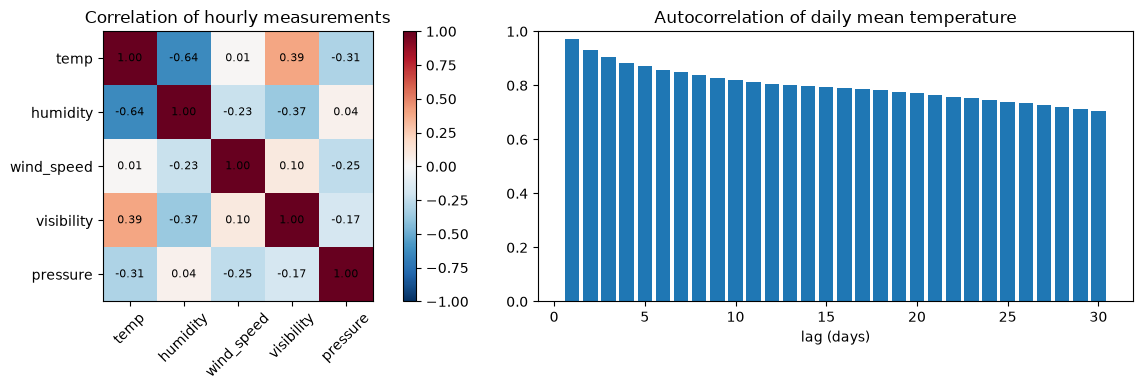

Day-to-day change of the daily mean: mean |change| = 1.63 °C, std = 2.16 °C, largest drop = -11.0 °C, largest rise = 11.3 °C


In [7]:
num = df[["temp", "humidity", "wind_speed", "visibility", "pressure"]]
corr = num.corr()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); fig.colorbar(im, ax=ax[0])
ax[0].set_xticks(range(len(corr)), corr.columns, rotation=45); ax[0].set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Correlation of hourly measurements")
lags = range(1, 31)
ax[1].bar(lags, [daily_temp.autocorr(l) for l in lags])
ax[1].set_title("Autocorrelation of daily mean temperature"); ax[1].set_xlabel("lag (days)"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

change = daily_temp.diff().dropna()
print(f"Day-to-day change of the daily mean: mean |change| = {change.abs().mean():.2f} °C, "
      f"std = {change.std():.2f} °C, largest drop = {change.min():.1f} °C, largest rise = {change.max():.1f} °C")

**Conclusions**
- Lag-1 autocorrelation ≈ 0.97: tomorrow is usually close to today. "Tomorrow = today" (**persistence**) is a strong baseline that every model must beat.
- Because tomorrow ≈ today, we also test predicting the **change** (tomorrow − today) instead of the absolute value (§7, stage *target*).
- Humidity is strongly anti-correlated with temperature. Pressure barely correlates with temperature directly, but pressure *changes* signal weather fronts, so we keep it and also compute its daily change.
- The daily mean usually changes by about 1.6 °C from one day to the next, but sometimes by up to 11 °C (cold fronts, sudden warm-ups). These jumps are the hardest days to predict (§10).

In [8]:
print("Precip Type:", df["precip_type"].value_counts(dropna=False).to_dict())
print("Temperature range of 'snow' hours:", df.loc[df["precip_type"] == "snow", "temp"].agg(["min", "max"]).to_dict())
print(df["summary"].nunique(), "hourly summaries |", df["daily_summary"].nunique(), "daily summaries")
print(df["summary"].value_counts().head(8).to_dict())

Precip Type: {'rain': 85200, 'snow': 10712, nan: 517}
Temperature range of 'snow' hours: {'min': -21.822222222222223, 'max': 0.0}
27 hourly summaries | 214 daily summaries
{'Partly Cloudy': 31726, 'Mostly Cloudy': 28094, 'Overcast': 16597, 'Clear': 10873, 'Foggy': 7148, 'Breezy and Overcast': 528, 'Breezy and Mostly Cloudy': 516, 'Breezy and Partly Cloudy': 386}


- **Issue 6 – `Precip Type` isn't precipitation.** Almost every hour is `rain` or `snow`, including clear hours, and `snow` appears exactly when the temperature is ≤ 0 °C. It's a re-encoding of temperature, so we don't use it.
- **`Summary`** (27 hourly labels) mainly describes cloud cover. We turn it into numbers: a cloudiness scale (Clear 0 … Overcast 3) plus fog, wind and rain flags.
- **`Daily Summary`** (214 sentences): tested as an extra text input with a multi-hot bag of words, as in Class 2 (§7, stage *extra_inputs*).

## 4. Feature engineering

**Hourly features** (computed for every hour; `hourly_features` below):

| Feature | Why |
|---|---|
| temperature, humidity, visibility, pressure | raw measurements (standardised) |
| **dew point** (Magnus formula) | combines temperature and humidity into the actual amount of moisture in the air. Moist air cools less at night. |
| wind speed + **wind u/v components** | the wind direction is an angle (359° and 1° are neighbours), so it's turned into east/north vectors |
| **cloudiness, fog, windy, rain** | numeric versions of the `Summary` text; clouds limit daytime heating and night-time cooling |
| **hour of day** (sin, cos) | lets the model know where in the daily cycle each reading is |

**Daily features** (one row per day; `daily_table` below): mean, min and max temperature, the **last-hour temperature**, the **temperature trend over the last 6 hours**, mean humidity, dew point, visibility, pressure, **pressure change during the day**, wind, and cloudiness/fog/wind/rain fractions.

**Calendar:** the day of the year of the *predicted* day as sin/cos, so 31 Dec and 1 Jan are neighbours.

In [9]:
CLOUD = {"Partly Cloudy": 1, "Mostly Cloudy": 2, "Overcast": 3, "Clear": 0}


def _cloudiness(s):
    for name, v in CLOUD.items():   # "Partly/Mostly Cloudy" checked before plain words
        if name in s:
            return v
    return np.nan


def hourly_features(df):
    """Numeric hourly features (used both for daily aggregates and the hourly model input)."""
    h = pd.DataFrame(index=df.index)
    h["temp"] = df["temp"]
    h["humidity"] = df["humidity"]
    # Dew point (Magnus formula): the temperature at which air becomes saturated.
    # Combines temperature and humidity into the amount of moisture in the air.
    a, b = 17.62, 243.12
    gamma = np.log(df["humidity"].clip(lower=0.01)) + a * df["temp"] / (b + df["temp"])
    h["dew_point"] = b * gamma / (a - gamma)
    h["visibility"] = df["visibility"]
    h["pressure"] = df["pressure"]
    rad = np.deg2rad(df["wind_bearing"])        # angle -> vector, so 359° and 1° are close
    h["wind_speed"] = df["wind_speed"]
    h["wind_u"] = df["wind_speed"] * np.sin(rad)
    h["wind_v"] = df["wind_speed"] * np.cos(rad)
    h["cloudiness"] = df["summary"].map(_cloudiness)
    h["cloudiness"] = h["cloudiness"].fillna(h["cloudiness"].rolling(6, min_periods=1).mean()).fillna(1.5)
    h["fog"] = df["summary"].str.contains("Fog").astype(float)
    h["windy"] = df["summary"].str.contains("Breezy|Windy").astype(float)
    h["rain"] = df["summary"].str.contains("Rain|Drizzle").astype(float)
    return h

In [10]:
def daily_table(df, h):
    """One row per local calendar day."""
    g = h.resample("D")
    d = pd.DataFrame({
        "temp_mean": g["temp"].mean(), "temp_min": g["temp"].min(), "temp_max": g["temp"].max(),
        "temp_last": g["temp"].last(),
        # temperature change over the last 6 hours of the day (evening trend)
        "temp_trend_6h": g["temp"].last() - h["temp"].resample("D").apply(lambda s: s.iloc[-7] if len(s) >= 7 else s.iloc[0]),
        "humidity": g["humidity"].mean(), "dew_point": g["dew_point"].mean(),
        "visibility": g["visibility"].mean(),
        "pressure": g["pressure"].mean(), "pressure_change": g["pressure"].last() - g["pressure"].first(),
        "wind_speed": g["wind_speed"].mean(), "wind_u": g["wind_u"].mean(), "wind_v": g["wind_v"].mean(),
        "cloudiness": g["cloudiness"].mean(), "fog": g["fog"].mean(), "windy": g["windy"].mean(),
        "rain": g["rain"].mean(),
    })
    d["daily_summary"] = df["daily_summary"].resample("D").first()
    d.index = d.index.tz_localize(None).normalize()
    num = d.columns.drop("daily_summary")
    d[num] = d[num].interpolate()
    d["daily_summary"] = d["daily_summary"].ffill()
    return d


FEATURE_GROUPS = {
    "temperature": ["temp_mean", "temp_min", "temp_max", "temp_last", "temp_trend_6h"],
    "moisture": ["humidity", "dew_point"],
    "visibility": ["visibility"],
    "pressure": ["pressure", "pressure_change"],
    "wind": ["wind_speed", "wind_u", "wind_v"],
    "sky": ["cloudiness", "fog", "windy", "rain"],
}


HOURLY_COLS = ["temp", "humidity", "dew_point", "visibility", "pressure",
               "wind_speed", "wind_u", "wind_v", "cloudiness", "fog", "windy", "rain"]

## 5. Windows, split and normalisation

- **Sample:** for a target day *t*, the inputs are days *t-3, t-2, t-1* (as 3 daily rows and/or the 72 hourly rows before local midnight) and the output is the mean temperature of day *t*.
- **Split by time, not at random.** Neighbouring days are nearly identical, so a random split would leak test information into training (temporal leakage, Class 1). We use:
  train **2006–2013** · validation **2014–2015** (all model choices) · test **2016** (used **once**, at the very end).
- **Normalisation** statistics (mean/std) come **from the training rows only**. The **target is scaled too** (`regression.ipynb`: "we can simply scale the outputs and then scale them back"). Predictions are converted back to °C before computing errors.
- **Metric: MAE in °C** – "on average we are X degrees off". **Loss: MSE** (Class 2 recommendation for regression).

`Dataset` builds every sample at once: the 3 daily rows, the 72 hourly rows, the calendar values, the 3 `Daily Summary` sentences and the target. `mask()` returns which samples belong to train, validation, test or a block of years (for K-fold).

In [11]:
class Dataset:
    """All model inputs for every target day, plus the time-based split.

    Sample for target day t: days t-3..t-1 (daily rows, 72 hourly rows, 3 daily summaries)
    + day-of-year of t  ->  mean temperature of day t.
    """

    def __init__(self, cfg, verbose=False):
        self.cfg = cfg
        df = load_clean(cfg, verbose=verbose)
        self.hourly_raw = df
        h = hourly_features(df)
        self.daily = daily_table(df, h)
        W = cfg["data"]["window_days"]

        # Regular UTC hourly grid (no DST jumps); fill the few missing hours by interpolation.
        hu = h.tz_convert("UTC")
        hu = hu.reindex(pd.date_range(hu.index.min(), hu.index.max(), freq="h")).interpolate()
        hour_local = hu.index.tz_convert(cfg["data"]["timezone"]).hour
        hu["hour_sin"] = np.sin(2 * np.pi * hour_local / 24)
        hu["hour_cos"] = np.cos(2 * np.pi * hour_local / 24)
        self.hourly_cols = HOURLY_COLS + ["hour_sin", "hour_cos"]
        hv = hu[self.hourly_cols].to_numpy("float32")
        h_index = hu.index

        days = self.daily.index
        self.dates = days[W:]
        all_feats = [c for g in FEATURE_GROUPS.values() for c in g]
        dv = self.daily[all_feats].to_numpy("float32")
        self.daily_cols = all_feats
        self.X_daily = np.stack([dv[t - W:t] for t in range(W, len(days))])

        # 72 hours before local midnight of the target day
        midnights = (self.dates.tz_localize(cfg["data"]["timezone"]).tz_convert("UTC"))
        pos = h_index.get_indexer(midnights)
        assert (pos >= W * 24).all() and (pos >= 0).all()
        self.X_hourly = np.stack([hv[p - W * 24:p] for p in pos])

        doy = self.dates.dayofyear.to_numpy()
        self.X_cal = np.stack([np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)], 1).astype("float32")
        texts = self.daily["daily_summary"].to_numpy()
        self.texts = np.array([" | ".join(texts[t - W:t]) for t in range(W, len(days))])
        self.y = self.daily["temp_mean"].to_numpy("float32")[W:]
        self.last_mean = self.X_daily[:, -1, all_feats.index("temp_mean")]

    def mask(self, part, years=None):
        d, c = self.dates, self.cfg["data"]
        if part == "train":
            return d <= c["train_end"]
        if part == "val":
            return (d > c["train_end"]) & (d <= c["val_end"])
        if part == "test":
            return d > c["val_end"]
        if part == "trainval":
            return d <= c["val_end"]
        if part == "years":
            return np.isin(d.year, years)
        raise ValueError(part)

In [12]:
ds = Dataset(CONFIG)
print("samples:", len(ds.y))
print("daily input  :", ds.X_daily.shape[1:], "=", ds.X_daily.shape[1], "days ×", len(ds.daily_cols), "features")
print("hourly input :", ds.X_hourly.shape[1:], "=", ds.X_hourly.shape[1], "hours ×", len(ds.hourly_cols), "features")
print("calendar     :", ds.X_cal.shape[1:])
print("text example :", ds.texts[0])
ds.daily.drop(columns="daily_summary").head(3).round(2)

samples: 4015
daily input  : (3, 17) = 3 days × 17 features
hourly input : (72, 14) = 72 hours × 14 features
calendar     : (2,)
text example : Mostly cloudy throughout the day. | Overcast throughout the day. | Mostly cloudy throughout the day.


,temp_mean,temp_min,temp_max,temp_last,temp_trend_6h,humidity,dew_point,visibility,pressure,pressure_change,wind_speed,wind_u,wind_v,cloudiness,fog,windy,rain
time,,,,,,,,,,,,,,,,,
2006-01-01,3.87,0.58,7.44,5.42,-0.48,0.82,1.03,11.11,1012.28,-7.02,21.37,13.11,-16.80,2.25,0.0,0.0,0.0
2006-01-02,5.42,1.69,7.51,1.69,-4.24,0.84,2.94,8.96,1010.13,5.67,17.55,5.03,-13.41,2.96,0.0,0.0,0.0
2006-01-03,2.32,1.67,2.90,2.20,-0.58,0.90,0.81,9.01,1020.80,8.78,8.42,-6.23,-3.10,2.58,0.0,0.0,0.0


In [13]:
for part in ["train", "val", "test"]:
    m = ds.mask(part)
    print(f"{part:5s}: {m.sum():5d} samples  {ds.dates[m].min().date()} → {ds.dates[m].max().date()}")

train:  2919 samples  2006-01-04 → 2013-12-31
val  :   730 samples  2014-01-01 → 2015-12-31
test :   366 samples  2016-01-01 → 2016-12-31


### Scaling, model and training code

- **`Prepared`** fits all scaling on the training rows of one experiment only: inputs and the target, as in `regression.ipynb`. It can drop feature groups (for the ablation) and converts predictions back to °C. With `target: delta` it also adds back today's mean.
- **`build_model`** builds a functional-API model (Class 3) from a parameter dictionary. It uses one branch per input (hourly / daily: flatten, GRU, LSTM or Conv1D), then dense layers with optional dropout and L2, and `Dense(1)` with no activation, for regression.
- **`train_eval`** trains one model with a fixed seed. Given a validation set, it uses early stopping (and optionally ReduceLROnPlateau) and returns the validation MAE in °C. Without one, it trains for a fixed number of epochs (the final retraining).

In [14]:
class Prepared:
    """Scales inputs/target with statistics from the training rows only."""

    def __init__(self, ds, train_mask, p):
        self.ds, self.p = ds, p
        cols = [c for g, cs in FEATURE_GROUPS.items() if g not in p.get("drop_groups", []) for c in cs]
        self.col_idx = [ds.daily_cols.index(c) for c in cols]
        hcols = [c for c in ds.hourly_cols if not _hourly_in_dropped(c, p.get("drop_groups", []))]
        self.hcol_idx = [ds.hourly_cols.index(c) for c in hcols]
        Xd = ds.X_daily[train_mask][:, :, self.col_idx]
        Xh = ds.X_hourly[train_mask][:, :, self.hcol_idx]
        self.mu_d, self.sd_d = Xd.reshape(-1, Xd.shape[-1]).mean(0), Xd.reshape(-1, Xd.shape[-1]).std(0) + 1e-6
        self.mu_h, self.sd_h = Xh.reshape(-1, Xh.shape[-1]).mean(0), Xh.reshape(-1, Xh.shape[-1]).std(0) + 1e-6
        t = self._raw_target(train_mask)
        self.mu_y, self.sd_y = float(t.mean()), float(t.std())   # target scaling (Class 2, regression)
        if p.get("text"):
            self.vec = keras.layers.TextVectorization(max_tokens=300, output_mode="multi_hot")
            self.vec.adapt(ds.texts[train_mask])

    def _raw_target(self, m):
        y = self.ds.y[m]
        return y - self.ds.last_mean[m] if self.p["target"] == "delta" else y

    def inputs(self, m):
        ds, p, x = self.ds, self.p, {}
        if p["input"] in ("daily", "both"):
            x["daily"] = (ds.X_daily[m][:, :, self.col_idx] - self.mu_d) / self.sd_d
        if p["input"] in ("hourly", "both"):
            x["hourly"] = (ds.X_hourly[m][:, :, self.hcol_idx] - self.mu_h) / self.sd_h
        if p.get("calendar", True):
            x["cal"] = ds.X_cal[m]
        if p.get("text"):
            x["text"] = self.vec(ds.texts[m]).numpy().astype("float32")
        return x

    def target(self, m):
        return ((self._raw_target(m) - self.mu_y) / self.sd_y).astype("float32")

    def to_celsius(self, pred_scaled, m):
        pred = pred_scaled.ravel() * self.sd_y + self.mu_y
        return pred + self.ds.last_mean[m] if self.p["target"] == "delta" else pred


def _hourly_in_dropped(col, groups):
    owner = {"temp": "temperature", "humidity": "moisture", "dew_point": "moisture", "visibility": "visibility",
             "pressure": "pressure", "wind_speed": "wind", "wind_u": "wind", "wind_v": "wind",
             "cloudiness": "sky", "fog": "sky", "windy": "sky", "rain": "sky"}
    return owner.get(col) in groups

In [15]:
def build_model(p, shapes, seed):
    """Functional-API model (Class 3) with up to four inputs."""
    L = keras.layers
    init = lambda: keras.initializers.GlorotUniform(seed=seed)
    reg = keras.regularizers.l2(p["l2"]) if p.get("l2") else None
    ins, parts = [], []

    def seq_branch(name, arch, units):
        i = keras.Input(shape=shapes[name], name=name); ins.append(i)
        if arch == "flatten":
            return L.Flatten()(i)
        if arch == "conv1d":
            x = L.Conv1D(units, 5, activation="relu", padding="same", kernel_initializer=init())(i)
            x = L.MaxPooling1D(3)(x)
            x = L.Conv1D(units, 3, activation="relu", padding="same", kernel_initializer=init())(x)
            return L.GlobalAveragePooling1D()(x)
        rnn = {"lstm": L.LSTM, "gru": L.GRU}[arch]
        layer = rnn(units, kernel_initializer=init(), seed=seed, dropout=p.get("rnn_dropout", 0.0))
        return (L.Bidirectional(layer) if p.get("bidirectional") else layer)(i)

    if p["input"] in ("daily", "both"):
        parts.append(seq_branch("daily", p["daily_arch"], p["units"]))
    if p["input"] in ("hourly", "both"):
        parts.append(seq_branch("hourly", p["hourly_arch"], p["units"]))
    for name in ("cal", "text"):
        if name in shapes:
            i = keras.Input(shape=shapes[name], name=name); ins.append(i)
            parts.append(L.Dense(16, activation="relu", kernel_initializer=init())(i) if name == "text" else i)
    x = parts[0] if len(parts) == 1 else L.Concatenate()(parts)
    for u in p["dense"]:
        x = L.Dense(u, activation="relu", kernel_initializer=init(), kernel_regularizer=reg)(x)
        if p.get("dropout"):
            x = L.Dropout(p["dropout"], seed=seed)(x)
    out = L.Dense(1, kernel_initializer=init())(x)   # regression: no activation
    return keras.Model(ins, out)

In [16]:
def train_eval(ds, p, seed, train_m, val_m=None, epochs=None, log_csv=None, return_model=False):
    """Train one model. With val_m: early stopping on it and MAE (°C) returned.
    Without val_m: train for a fixed number of epochs (final retraining on train+val)."""
    set_seed(seed)
    prep = Prepared(ds, train_m, p)
    xtr, ytr = prep.inputs(train_m), prep.target(train_m)
    shapes = {k: v.shape[1:] for k, v in xtr.items()}
    model = build_model(p, shapes, seed)
    loss = keras.losses.Huber(delta=1.0) if p.get("loss") == "huber" else "mse"
    model.compile(optimizer=keras.optimizers.Adam(p["lr"]), loss=loss, metrics=["mae"])
    cbs = []
    if log_csv:
        Path(log_csv).parent.mkdir(parents=True, exist_ok=True)
        cbs.append(keras.callbacks.CSVLogger(str(log_csv)))
    fit_kw = dict(epochs=epochs or p["epochs"], batch_size=p["batch_size"], verbose=0, shuffle=True)
    if val_m is not None:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=p["patience"], restore_best_weights=True))
        if p.get("reduce_lr"):
            cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, p["patience"] // 3)))
        fit_kw["validation_data"] = (prep.inputs(val_m), prep.target(val_m))
    elif p.get("reduce_lr"):   # final retraining has no validation set: follow training loss instead
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=max(2, p["patience"] // 3)))
    hist = model.fit(xtr, ytr, callbacks=cbs, **fit_kw)
    res = {"epochs_run": len(hist.history["loss"])}
    if val_m is not None:
        res["best_epoch"] = int(np.argmin(hist.history["val_loss"]) + 1)
        pred = prep.to_celsius(model.predict(prep.inputs(val_m), verbose=0, batch_size=1024), val_m)
        res["val_mae"] = float(np.mean(np.abs(pred - ds.y[val_m])))
    if return_model:
        return res, model, prep, hist
    return res


def predict_celsius(model, prep, m):
    return prep.to_celsius(model.predict(prep.inputs(m), verbose=0, batch_size=1024), m)

## 6. Baselines without learning

In [17]:
va, tr = ds.mask("val"), ds.mask("train")
clim = (pd.Series(ds.y[tr], index=ds.dates[tr].dayofyear).groupby(level=0).mean()
        .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
baselines = {
    "persistence (tomorrow = today)": np.abs(ds.last_mean[va] - ds.y[va]).mean(),
    "climatology (average for this day of year)": np.abs(clim.loc[ds.dates[va].dayofyear].to_numpy() - ds.y[va]).mean(),
}
for k, v in baselines.items():
    print(f"validation MAE {v:.3f} °C – {k}")

validation MAE 1.525 °C – persistence (tomorrow = today)
validation MAE 2.852 °C – climatology (average for this day of year)



### Why "tomorrow = today" is the bar to beat

Persistence needs no model at all, yet it's hard to beat. The plots below use the validation years (2014–2015):
1. **A two-month zoom:** the persistence forecast is simply the actual curve shifted by one day. It follows the real temperature closely and is only wrong right after a change.
2. **Today vs tomorrow:** almost every day lies close to the "tomorrow = today" line.
3. **Error distribution:** most persistence errors are small; a few days with big jumps produce the large ones.


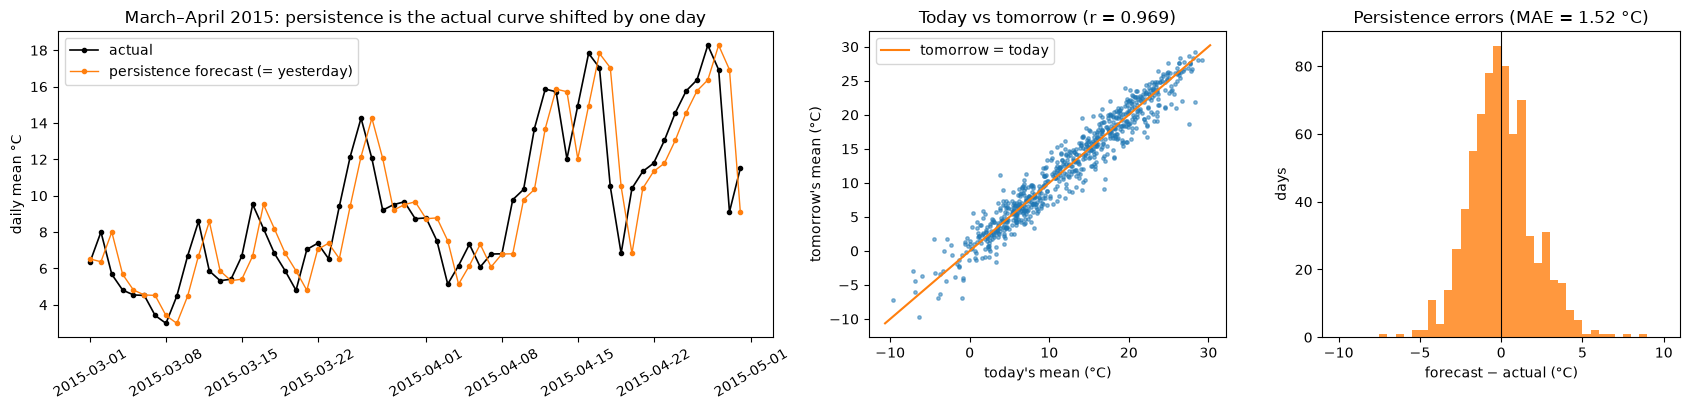

Persistence on validation: MAE 1.52 °C | within 1 °C on 42 % of days, within 2 °C on 72 % | off by more than 4 °C on 5.1 % of days
Climatology on validation: MAE 2.85 °C – knowing the season alone is much worse than knowing yesterday


In [18]:

d_va, y_va, p_va = ds.dates[va], ds.y[va], ds.last_mean[va]
err = p_va - y_va
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [2, 1, 1]})

z = (d_va >= "2015-03-01") & (d_va <= "2015-04-30")
ax[0].plot(d_va[z], y_va[z], "k-o", ms=3, lw=1.2, label="actual")
ax[0].plot(d_va[z], p_va[z], "-o", color="tab:orange", ms=3, lw=1, label="persistence forecast (= yesterday)")
ax[0].set_title("March–April 2015: persistence is the actual curve shifted by one day"); ax[0].set_ylabel("daily mean °C")
ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)

ax[1].scatter(p_va, y_va, s=6, alpha=0.5)
lim = [min(p_va.min(), y_va.min()) - 1, max(p_va.max(), y_va.max()) + 1]
ax[1].plot(lim, lim, color="tab:orange", lw=1.5, label="tomorrow = today")
ax[1].set_xlabel("today's mean (°C)"); ax[1].set_ylabel("tomorrow's mean (°C)")
ax[1].set_title(f"Today vs tomorrow (r = {np.corrcoef(p_va, y_va)[0, 1]:.3f})"); ax[1].legend()

ax[2].hist(err, bins=np.arange(-10, 10.5, 0.5), color="tab:orange", alpha=0.8)
ax[2].axvline(0, color="k", lw=0.8)
ax[2].set_title(f"Persistence errors (MAE = {np.abs(err).mean():.2f} °C)"); ax[2].set_xlabel("forecast − actual (°C)"); ax[2].set_ylabel("days")
plt.tight_layout(); plt.show()

a = np.abs(err)
print(f"Persistence on validation: MAE {a.mean():.2f} °C | within 1 °C on {100 * (a <= 1).mean():.0f} % of days, "
      f"within 2 °C on {100 * (a <= 2).mean():.0f} % | off by more than 4 °C on {100 * (a > 4).mean():.1f} % of days")
print(f"Climatology on validation: MAE {baselines['climatology (average for this day of year)']:.2f} °C – "
      f"knowing the season alone is much worse than knowing yesterday")


**The goal of the project follows from this:**
- Persistence is within 1 °C on 42 % of days and within 2 °C on 72 %. It's only badly wrong (> 4 °C) on about 5 % of days, right after sudden changes.
- Knowing the season alone (climatology, 2.85 °C) is much worse than knowing yesterday (1.52 °C).
- **Goal: beat persistence**, i.e. get below **1.52 °C on validation** and **1.43 °C on the 2016 test year**. A model that doesn't beat it has learned nothing useful.
- Persistence already gets the level right, so the model can only add value by **anticipating changes**. This motivated predicting the change (`target=delta`) and giving the model inputs that signal change: the pressure trend, wind direction and the evening temperature trend.

## 7. Systematic experiments

**Starting point – the Class 2 tabular baseline:** standardised features → `Dense(64, relu)` → `Dense(32, relu)` → `Dense(1)`, Adam, MSE, batch 32, early stopping.

**Search procedure** (code below, settings in `config.yaml → search`). Following Class 2's "one parameter change per one test", each stage tries a few single changes on top of the current best configuration:

1. **target** – absolute temperature vs change from today
2. **input** – 3 daily rows vs 72 hourly rows (GRU / LSTM / Conv1D) vs both
3. **size** – units, dense head, bidirectional
4. **regularisation** – dropout, recurrent dropout, L2 (Class 2: only if overfitting)
5. **optimisation** – learning rate and batch size (Class 2: "usually sufficient to tune"), ReduceLROnPlateau (Class 3)
6. **loss** – MSE vs Huber
7. **extra inputs** – `Daily Summary` text, calendar removed

Every configuration is trained with **3 seeds**, and we compare **mean ± std** of validation MAE. A change is kept only if it lowers the mean.

**Experiment log and caching.** Each training run is identified by its configuration, seed and fold, and appended to `runs/experiments.jsonl`. When the notebook runs again, finished runs are read from the log instead of retrained. The same configuration and seed give exactly the same result (§11), so this changes nothing in the results. It only means the full search (≈ 55 min of training) doesn't have to be repeated. **To retrain everything from scratch, delete `runs/experiments.jsonl`.**

In [19]:
LOG = RUNS / "experiments.jsonl"


def key_of(params, seed, fold):
    s = json.dumps(params, sort_keys=True) + f"|{seed}|{fold}"
    return hashlib.sha1(s.encode()).hexdigest()[:16]


def load_cache():
    if not LOG.exists():
        return {}
    return {r["key"]: r for r in map(json.loads, LOG.read_text().splitlines())}


CACHE = load_cache()
print(len(CACHE), "finished runs found in the log")


def run(ds, params, seed, fold, phase, label, train_m, val_m):
    k = key_of(params, seed, fold)
    if k in CACHE:
        return CACHE[k]
    t0 = time.time()
    res = train_eval(ds, params, seed, train_m, val_m)
    rec = {"key": k, "phase": phase, "label": label, "seed": seed, "fold": fold,
           "params": params, **res, "seconds": round(time.time() - t0, 1)}
    with LOG.open("a") as f:
        f.write(json.dumps(rec) + "\n")
    CACHE[k] = rec
    print(f"  {phase:8s} {label:45s} seed {seed:5d} fold {fold}: val MAE {res['val_mae']:.3f}  "
          f"({res['epochs_run']} ep, {rec['seconds']}s)", flush=True)
    return rec


def score(ds, cfg, params, phase, label):
    tr, va = ds.mask("train"), ds.mask("val")
    maes = [run(ds, params, s, "val", phase, label, tr, va)["val_mae"] for s in cfg["seeds"]]
    return float(np.mean(maes)), float(np.std(maes, ddof=1))


def describe(variant):
    return ", ".join(f"{k}={v}" for k, v in variant.items())

219 finished runs found in the log


**The greedy search** – stages and variants come from `config.yaml → search`.

In [20]:
best = dict(CONFIG["baseline"])
best_mean, best_std = score(ds, CONFIG, best, "search", "baseline")
search_steps = [{"stage": "baseline", "change": "Class 2 baseline", "mean": best_mean, "std": best_std,
                 "kept": True, "params": best}]
for stage in CONFIG["search"]:
    stage_best = None
    for v in stage["variants"]:
        p = {**best, **v}
        if p == best:
            continue
        m, s = score(ds, CONFIG, p, "search", f"{stage['name']}: {describe(v)}")
        search_steps.append({"stage": stage["name"], "change": describe(v), "mean": m, "std": s,
                             "kept": False, "params": p})
        if m < best_mean and (stage_best is None or m < stage_best[0]):
            stage_best = (m, s, p, len(search_steps) - 1)
    if stage_best:
        best_mean, best_std, best, i = stage_best
        search_steps[i]["kept"] = True
    print(f"after stage '{stage['name']}': {best_mean:.3f} ± {best_std:.3f} °C")
pd.DataFrame(search_steps).drop(columns="params").round(4).to_csv(RUNS / "search_steps.csv", index=False)

after stage 'target': 1.268 ± 0.024 °C
after stage 'input': 1.178 ± 0.035 °C
after stage 'size': 1.161 ± 0.018 °C
after stage 'regularisation': 1.139 ± 0.016 °C
after stage 'optimisation': 1.134 ± 0.009 °C
after stage 'loss': 1.129 ± 0.009 °C
after stage 'extra_inputs': 1.129 ± 0.009 °C
after stage 'second_pass_input': 1.113 ± 0.014 °C
after stage 'second_pass_target': 1.107 ± 0.014 °C


In [21]:
log = pd.read_json(RUNS / "experiments.jsonl", lines=True)
print(f"Training runs logged: {len(log)} | distinct configurations: {log['params'].astype(str).nunique()} | "
      f"total training time: {log['seconds'].sum() / 60:.1f} min")
steps = pd.read_csv(RUNS / "search_steps.csv")
steps

Training runs logged: 219 | distinct configurations: 46 | total training time: 54.9 min


,stage,change,mean,std,kept
0,baseline,Class 2 baseline,1.4542,0.0498,True
1,target,target=delta,1.2681,0.0238,True
2,input,"input=hourly, hourly_arch=gru",1.2494,0.0445,False
3,input,"input=hourly, hourly_arch=lstm",1.2748,0.0019,False
4,input,"input=hourly, hourly_arch=conv1d",1.2904,0.0201,False
5,input,"input=both, hourly_arch=gru",1.2163,0.0453,False
6,input,"input=daily, daily_arch=gru",1.1775,0.0351,True
7,size,units=16,1.1895,0.0054,False
8,size,units=64,1.1669,0.0123,False
9,size,dense=[],1.1783,0.0171,False


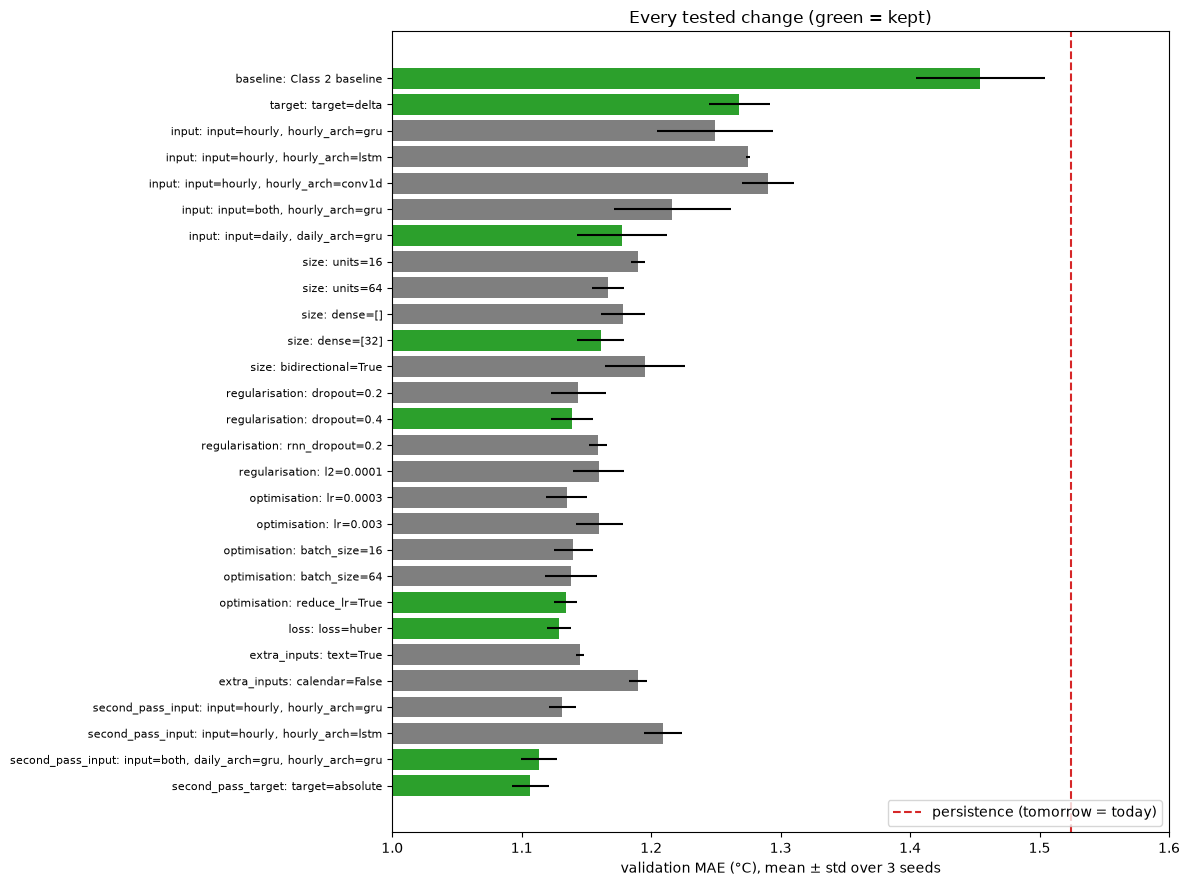

In [22]:
fig, ax = plt.subplots(figsize=(12, max(4, 0.32 * len(steps))))
yy = np.arange(len(steps))[::-1]
colors = ["tab:green" if k else "tab:gray" for k in steps["kept"]]
ax.barh(yy, steps["mean"], xerr=steps["std"], color=colors)
ax.set_yticks(yy, [f"{s}: {c}" for s, c in zip(steps["stage"], steps["change"])], fontsize=8)
for name, v in baselines.items():
    if v < 2:
        ax.axvline(v, color="tab:red", ls="--", label=name)
ax.set_xlim(1.0, max(1.6, steps["mean"].max() + 0.05)); ax.set_xlabel("validation MAE (°C), mean ± std over 3 seeds")
ax.set_title("Every tested change (green = kept)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**What the search showed**
- **Predicting the change instead of the temperature** (`target=delta`, 1.454 → 1.268 °C) was the biggest single gain. The network no longer has to reproduce the seasonal level (persistence already gives it). It only learns how tomorrow differs from today.
- **Reading the 3 days as a sequence with a GRU** (Class 2 `language.ipynb`) instead of flattening them: → 1.178 °C.
- **Dropout 0.4** (Class 2: "if overfitting → add Dropout") → 1.139 °C. With only about 2,900 training days, the network overfits quickly.
- Learning rate, batch size, ReduceLROnPlateau and the Huber loss changed results by ≤ 0.01 °C, which is within seed noise. This matches the Class 2 note that sensible defaults usually work.
- **Changes that made things worse:** the `Daily Summary` text (1.145), removing the calendar (1.190), a bidirectional GRU, LSTM and Conv1D.
- **Second pass – an important lesson about greedy search.** In the first pass the hourly input lost, because the input stage ran *before* dropout had been added, and the bigger hourly branch likely overfit. After tuning, we re-tested the input: **hourly + daily together** gave 1.113 °C. Results from a one-change-at-a-time search depend on the order of the stages, so it's worth revisiting early decisions at the end.

### Robustness: blocked K-fold over years

The validation set covers only 2 years, and differences of a few hundredths of a degree could be noise. Following `regression.ipynb` (K-fold for small datasets), we re-evaluate the top configurations with **5 folds of whole years**: 2006–07, 2008–09, 2010–11, 2012–13 and 2014–15. Each fold is validated once while training on the rest, with 3 seeds per fold (15 runs per configuration).

We use blocks of years rather than random rows, because random rows would leak neighbouring days. The configuration with the best K-fold mean is the final one. The median best epoch across the folds sets how long the final model is trained.

In [23]:
tried = {json.dumps(st["params"], sort_keys=True): st["mean"] for st in search_steps}
top = [json.loads(k) for k, _ in sorted(tried.items(), key=lambda kv: kv[1])[: CONFIG["cv"]["top_k"]]]
if best not in top:
    top.append(best)
cv_rows = []
for rank, p in enumerate(top):
    maes, epochs = [], []
    for years in CONFIG["cv"]["folds"]:
        fold_va = ds.mask("years", years)
        fold_tr = ds.mask("trainval") & ~fold_va
        for s in CONFIG["seeds"]:
            r = run(ds, p, s, f"{years[0]}-{years[-1]}", "cv", f"top{rank + 1}", fold_tr, fold_va)
            maes.append(r["val_mae"]); epochs.append(r["best_epoch"])
    cv_rows.append({"config": rank + 1,
                    "params": json.dumps({k: v for k, v in p.items() if CONFIG["baseline"].get(k) != v}),
                    "cv_mean": np.mean(maes), "cv_std": np.std(maes, ddof=1),
                    "median_best_epoch": int(np.median(epochs)), "full": p})
cv_df = pd.DataFrame(cv_rows)
cv_df.drop(columns="full").round(4).to_csv(RUNS / "cv.csv", index=False)
winner = cv_df.loc[cv_df["cv_mean"].idxmin()]
final_p, final_epochs = winner["full"], int(winner["median_best_epoch"])
(RUNS / "final_config.json").write_text(json.dumps({"params": final_p, "epochs": final_epochs}, indent=2))
print("K-fold winner:", winner["params"], "| epochs for the final training:", final_epochs)

K-fold winner: {"daily_arch": "gru", "dense": [32], "dropout": 0.4, "input": "both", "loss": "huber", "reduce_lr": true, "target": "delta"} | epochs for the final training: 29


In [24]:
cv = pd.read_csv(RUNS / "cv.csv")
cv

,config,params,cv_mean,cv_std,median_best_epoch
0,1,"{""daily_arch"": ""gru"", ""dense"": [32], ""dropout""...",1.1731,0.0381,35
1,2,"{""daily_arch"": ""gru"", ""dense"": [32], ""dropout""...",1.1558,0.0299,29
2,3,"{""daily_arch"": ""gru"", ""dense"": [32], ""dropout""...",1.2210,0.0509,31


### Feature ablation – which inputs matter?

Starting from the chosen configuration, we remove one feature group at a time (from both the hourly and daily inputs) and retrain with 3 seeds. A bigger increase in error means the group matters more.

In [25]:
win_mean, win_std = score(ds, CONFIG, final_p, "ablation", "winner, nothing dropped")
abl_rows = [{"dropped": "(none)", "mean": win_mean, "std": win_std}]
for g in CONFIG["ablation"]:
    m, s = score(ds, CONFIG, {**final_p, "drop_groups": [g]}, "ablation", f"drop {g}")
    abl_rows.append({"dropped": g, "mean": m, "std": s})
abl = pd.DataFrame(abl_rows)
abl["change_vs_full"] = abl["mean"] - win_mean
abl.round(4).to_csv(RUNS / "ablation.csv", index=False)

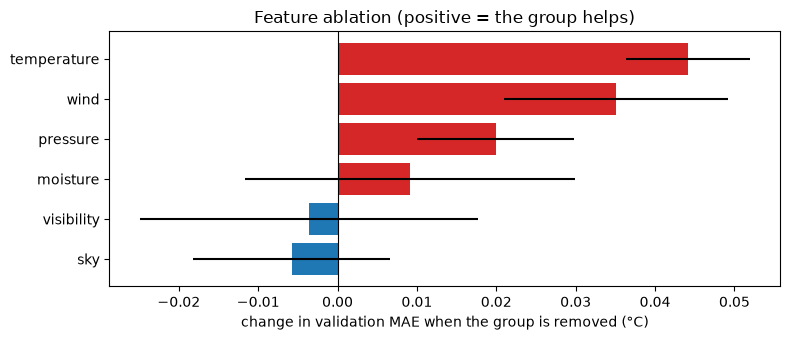

,dropped,mean,std,change_vs_full
0,(none),1.113,0.014,0.000
1,temperature,1.157,0.008,0.044
2,moisture,1.122,0.021,0.009
3,visibility,1.110,0.021,-0.004
4,pressure,1.133,0.010,0.020
5,wind,1.148,0.014,0.035
6,sky,1.107,0.012,-0.006


In [26]:
abl = pd.read_csv(RUNS / "ablation.csv")
a = abl[abl["dropped"] != "(none)"].sort_values("change_vs_full")
plt.figure(figsize=(8, 3.5))
plt.barh(a["dropped"], a["change_vs_full"], xerr=a["std"], color=["tab:red" if v > 0 else "tab:blue" for v in a["change_vs_full"]])
plt.axvline(0, color="k", lw=0.8); plt.xlabel("change in validation MAE when the group is removed (°C)")
plt.title("Feature ablation (positive = the group helps)"); plt.tight_layout(); plt.show()
abl.round(3)

**Conclusions**
- **Temperature history** matters most, as expected. **Wind** comes next: wind direction brings warm or cold air from elsewhere. **Pressure** (fronts) and **moisture** also help.
- Removing **visibility** or **sky** (cloudiness/fog flags) lowers the error very slightly, but the change (≤ 0.006 °C) is smaller than the spread between seeds (0.01–0.02 °C). So there's no evidence that these groups help. We kept them rather than tune further on the same validation set.

## 8. Live demonstration: course baseline vs final configuration

These two runs are re-trained here (seed 123) to show the difference live. All other numbers come from the logged runs.

In [27]:
print("Final configuration (differences from the baseline):")
print({k: v for k, v in final_p.items() if CONFIG["baseline"].get(k) != v})

demo = {}
for name, p in [("Class 2 baseline", CONFIG["baseline"]), ("final configuration", final_p)]:
    res, model, prep, hist = train_eval(ds, p, 123, tr, va, return_model=True)
    demo[name] = (model, prep, hist)
    print(f"{name:20s}: validation MAE {res['val_mae']:.3f} °C (best epoch {res['best_epoch']})")

Final configuration (differences from the baseline):
{'daily_arch': 'gru', 'dense': [32], 'dropout': 0.4, 'input': 'both', 'loss': 'huber', 'reduce_lr': True, 'target': 'delta'}


E0000 00:00:1793030588.135051 19165394 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Class 2 baseline    : validation MAE 1.444 °C (best epoch 20)


final configuration : validation MAE 1.118 °C (best epoch 53)


E0000 00:00:1793030624.438655 19165394 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


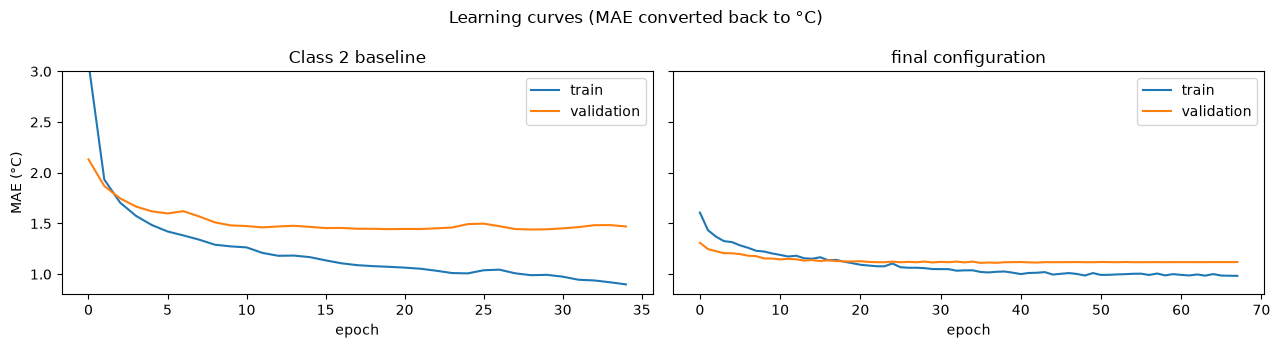

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for a, (name, (_, prep, hist)) in zip(ax, demo.items()):
    a.plot(np.array(hist.history["mae"]) * prep.sd_y, label="train")
    a.plot(np.array(hist.history["val_mae"]) * prep.sd_y, label="validation")
    a.set_title(name); a.set_xlabel("epoch"); a.legend()
ax[0].set_ylabel("MAE (°C)"); ax[0].set_ylim(0.8, 3)
plt.suptitle("Learning curves (MAE converted back to °C)"); plt.tight_layout(); plt.show()

## 9. Final architecture

In [29]:
demo["final configuration"][0].summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ daily (InputLayer)  │ (None, 3, 17)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hourly (InputLayer) │ (None, 72, 14)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 32)        │      4,896 │ daily[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 32)        │      4,608 │ hourly[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cal (InputLayer)    │ (None, 2)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 66)        │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ gru_1[0][0],      │
│                     │                   │            │ cal[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,144 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         33 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 35,045 (136.90 KB)

 Trainable params: 11,681 (45.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,364 (91.27 KB)

**Final network (functional API, three inputs)**

```
hourly: 72 h × 14 features ──► GRU(32) ──┐
daily :  3 d × 17 features ──► GRU(32) ──┼─► Concatenate ─► Dense(32, relu) ─► Dropout(0.4) ─► Dense(1)
calendar: day of year (sin, cos) ────────┘
```

- **Output:** the standardised *change* in daily mean temperature (tomorrow − today). In °C, prediction = today's mean + predicted change.
- **Why GRUs:** the inputs are time-ordered sequences (Class 2, `language.ipynb`). A GRU has fewer parameters than an LSTM, and it did better here (hourly GRU 1.13 vs LSTM 1.21 °C).
- **Why two branches:** the hourly branch sees the daily cycle and the latest hours; the daily branch sees compact summaries (min/max, pressure change, trends). Together they beat either alone.
- **Loss: Huber (δ = 1).** It behaves like MSE for small errors and like MAE for large ones, so sudden cold fronts don't dominate training.
- **Optimiser:** Adam (lr 0.001, halved by ReduceLROnPlateau), batch 32, early stopping (patience 15) during the search. The final model is trained for the 29 epochs found by K-fold.

## 10. Final result on the test set (2016)

The final configuration is retrained from scratch on **2006–2015** (train + validation, as in the "training the final model" step of `regression.ipynb`) for the number of epochs chosen by K-fold. This is done with each of the 3 seeds. It is then evaluated **once** on 2016, which was never used for any decision.

In [30]:
if CONFIG["run_test"]:
    tv, te = ds.mask("trainval"), ds.mask("test")
    out = RUNS / "final"; out.mkdir(exist_ok=True)
    preds, maes = [], []
    for s in CONFIG["seeds"]:
        _, model, prep, _ = train_eval(ds, final_p, s, tv, epochs=final_epochs,
                                       log_csv=out / f"history_seed_{s}.csv", return_model=True)
        model.save(out / f"model_seed_{s}.keras")
        pred = predict_celsius(model, prep, te)
        preds.append(pred); maes.append(float(np.mean(np.abs(pred - ds.y[te]))))
    ens = np.mean(preds, axis=0)
    y_te, dates_te = ds.y[te], ds.dates[te]
    clim_tv = (pd.Series(ds.y[tv], index=ds.dates[tv].dayofyear).groupby(level=0).mean()
               .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
    summary = {
        "test_mae_mean": float(np.mean(maes)), "test_mae_std": float(np.std(maes, ddof=1)),
        "test_mae_per_seed": maes,
        "test_mae_seed_ensemble": float(np.mean(np.abs(ens - y_te))),
        "test_rmse_seed_ensemble": float(np.sqrt(np.mean((ens - y_te) ** 2))),
        "test_persistence_mae": float(np.mean(np.abs(ds.last_mean[te] - y_te))),
        "test_climatology_mae": float(np.mean(np.abs(clim_tv.loc[dates_te.dayofyear].to_numpy() - y_te))),
        "epochs": final_epochs, "params": final_p,
    }
    (out / "test_summary.json").write_text(json.dumps(summary, indent=2))
    pd.DataFrame({"date": dates_te, "actual": y_te, "ensemble": ens, "persistence": ds.last_mean[te],
                  **{f"seed_{s}": p for s, p in zip(CONFIG["seeds"], preds)}}).to_csv(out / "test_predictions.csv", index=False)
else:
    print("run_test is false in config.yaml – the test set is not used.")

E0000 00:00:1793030642.061341 19165394 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


E0000 00:00:1793030659.661626 19165394 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


E0000 00:00:1793030678.195935 19165394 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


In [31]:
test = json.loads((RUNS / "final" / "test_summary.json").read_text())
tp = pd.read_csv(RUNS / "final" / "test_predictions.csv", parse_dates=["date"])
print(f"Final model, 3 seeds : test MAE {test['test_mae_mean']:.3f} ± {test['test_mae_std']:.3f} °C  "
      f"(per seed: {', '.join(f'{v:.3f}' for v in test['test_mae_per_seed'])})")
print(f"Average of the 3 seeds: test MAE {test['test_mae_seed_ensemble']:.3f} °C, RMSE {test['test_rmse_seed_ensemble']:.3f} °C")
print(f"Persistence baseline : test MAE {test['test_persistence_mae']:.3f} °C")
print(f"Climatology baseline : test MAE {test['test_climatology_mae']:.3f} °C")
print(f"Improvement over persistence: {100 * (1 - test['test_mae_mean'] / test['test_persistence_mae']):.0f} %")
first = json.loads((RUNS / "final_first_pass" / "test_summary.json").read_text())
print(f"(First-pass model, before the second-pass stage: test MAE {first['test_mae_mean']:.3f} ± {first['test_mae_std']:.3f} °C)")

Final model, 3 seeds : test MAE 1.269 ± 0.048 °C  (per seed: 1.254, 1.231, 1.323)
Average of the 3 seeds: test MAE 1.232 °C, RMSE 1.631 °C
Persistence baseline : test MAE 1.428 °C
Climatology baseline : test MAE 2.535 °C
Improvement over persistence: 11 %
(First-pass model, before the second-pass stage: test MAE 1.287 ± 0.014 °C)


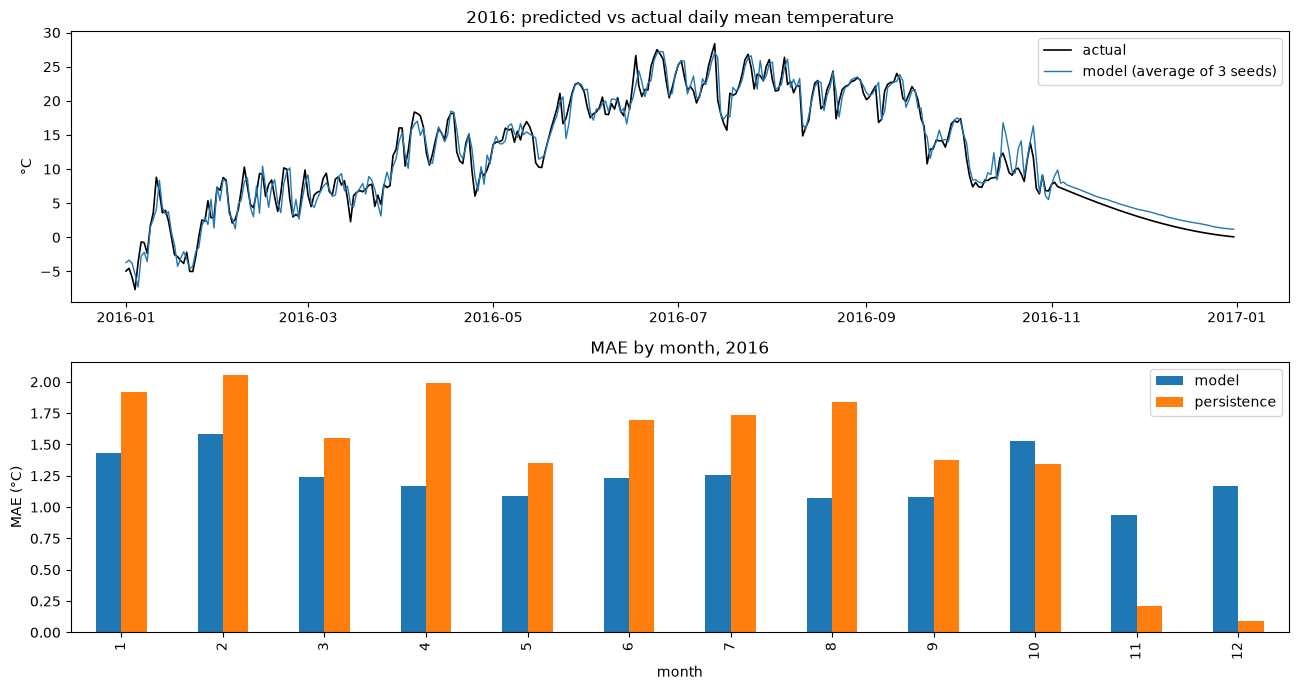

Five largest errors (note the size of the day-to-day change):


/var/folders/kz/jyvj1ds150g0xkk5bcx5gg7r0000gn/T/ipykernel_77649/1841268091.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  big.reindex(big["error"].abs().sort_values(ascending=False).index).head(5)[["date", "actual", "ensemble", "persistence", "error", "change"]].round(1)


,date,actual,ensemble,persistence,error,change
195,2016-07-14,20.1,26.3,28.4,6.2,-8.3
248,2016-09-05,16.8,22.7,22.2,5.9,-5.3
44,2016-02-14,9.4,3.5,6.5,-5.8,2.9
295,2016-10-22,9.3,14.1,10.1,4.8,-0.8
10,2016-01-11,8.8,4.1,3.6,-4.7,5.2


In [32]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(tp["date"], tp["actual"], label="actual", lw=1.2, color="k")
ax[0].plot(tp["date"], tp["ensemble"], label="model (average of 3 seeds)", lw=1)
ax[0].set_title("2016: predicted vs actual daily mean temperature"); ax[0].set_ylabel("°C"); ax[0].legend()
err_m = (tp["ensemble"] - tp["actual"]).abs(); err_p = (tp["persistence"] - tp["actual"]).abs()
monthly = pd.DataFrame({"model": err_m.groupby(tp["date"].dt.month).mean(),
                        "persistence": err_p.groupby(tp["date"].dt.month).mean()})
monthly.plot.bar(ax=ax[1]); ax[1].set_title("MAE by month, 2016"); ax[1].set_ylabel("MAE (°C)"); ax[1].set_xlabel("month")
plt.tight_layout(); plt.show()

big = tp.assign(error=tp["ensemble"] - tp["actual"], change=tp["actual"] - tp["persistence"])
print("Five largest errors (note the size of the day-to-day change):")
big.reindex(big["error"].abs().sort_values(ascending=False).index).head(5)[["date", "actual", "ensemble", "persistence", "error", "change"]].round(1)


### Goal check: did we beat "tomorrow = today"?

The goal set in §6 was to beat persistence. The chart compares all approaches on 2016. The table below shows **where** the model gains: we split the test days by how much the temperature actually changed from the day before.


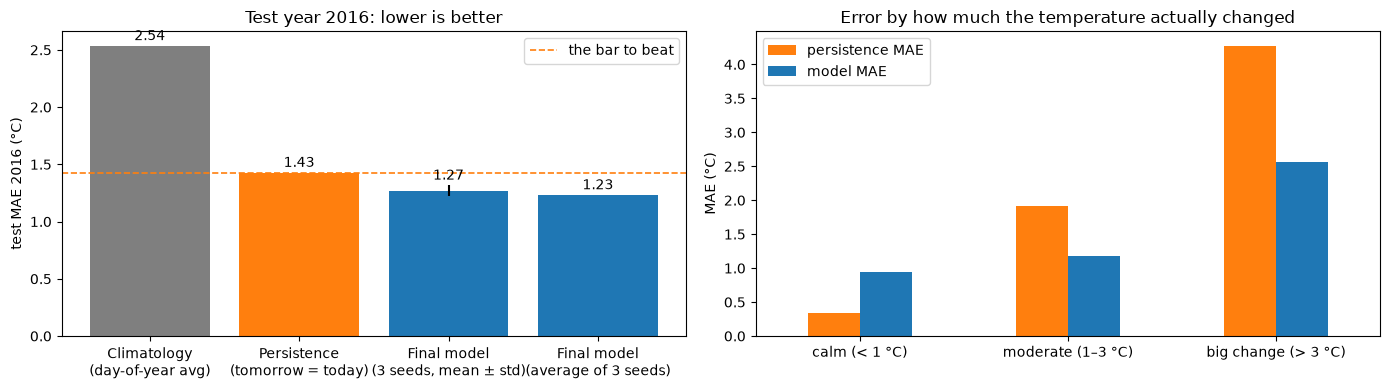

Model beats persistence by 0.16 °C (11 %); with the seed average by 0.20 °C (14 %)
Model closer to the truth than persistence on 54 % of the 366 days


,days,persistence MAE,model MAE
calm (< 1 °C),181,0.34,0.94
moderate (1–3 °C),140,1.91,1.18
big change (> 3 °C),45,4.27,2.57


In [33]:

chg = (tp["actual"] - tp["persistence"]).abs()
err_model = (tp["ensemble"] - tp["actual"]).abs()
err_pers = (tp["persistence"] - tp["actual"]).abs()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
names = ["Climatology\n(day-of-year avg)", "Persistence\n(tomorrow = today)", "Final model\n(3 seeds, mean ± std)", "Final model\n(average of 3 seeds)"]
vals = [test["test_climatology_mae"], test["test_persistence_mae"], test["test_mae_mean"], test["test_mae_seed_ensemble"]]
bars = ax[0].bar(names, vals, yerr=[0, 0, test["test_mae_std"], 0], color=["tab:gray", "tab:orange", "tab:blue", "tab:blue"])
ax[0].axhline(test["test_persistence_mae"], color="tab:orange", ls="--", lw=1.2, label="the bar to beat")
for b, v, e in zip(bars, vals, [0, 0, test["test_mae_std"], 0]):
    ax[0].text(b.get_x() + b.get_width() / 2, v + e + 0.05, f"{v:.2f}", ha="center")
ax[0].set_ylabel("test MAE 2016 (°C)"); ax[0].set_title("Test year 2016: lower is better"); ax[0].legend()

bins = pd.cut(chg, [0, 1, 3, 20], labels=["calm (< 1 °C)", "moderate (1–3 °C)", "big change (> 3 °C)"], include_lowest=True)
by = pd.DataFrame({"days": bins.value_counts().sort_index(),
                   "persistence MAE": err_pers.groupby(bins, observed=False).mean(),
                   "model MAE": err_model.groupby(bins, observed=False).mean()})
by[["persistence MAE", "model MAE"]].plot.bar(ax=ax[1], color=["tab:orange", "tab:blue"], rot=0)
ax[1].set_title("Error by how much the temperature actually changed"); ax[1].set_ylabel("MAE (°C)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(f"Model beats persistence by {test['test_persistence_mae'] - test['test_mae_mean']:.2f} °C "
      f"({100 * (1 - test['test_mae_mean'] / test['test_persistence_mae']):.0f} %); with the seed average by "
      f"{test['test_persistence_mae'] - test['test_mae_seed_ensemble']:.2f} °C "
      f"({100 * (1 - test['test_mae_seed_ensemble'] / test['test_persistence_mae']):.0f} %)")
print(f"Model closer to the truth than persistence on {100 * (err_model < err_pers).mean():.0f} % of the 366 days")
by.round(2)


**Goal reached**
- The final model beats persistence on the unseen year: **1.27 °C vs 1.43 °C (−11 %)**, or **1.23 °C (−14 %)** when the 3 seeds' predictions are averaged.
- It's closer to the truth than persistence on only **54 % of days**. The gain doesn't come from being better every day; it comes from **far fewer large misses**.
- On the 45 days with a **big change (> 3 °C)**, the model's error is 2.57 °C against 4.27 °C for persistence. On moderate days it's 1.18 against 1.91 °C. It catches part of the coming change from the pressure trend, the wind and the evening temperatures.
- On **calm days** persistence wins (0.34 vs 0.94 °C): the model sometimes predicts a change that doesn't come. Note that the days are grouped by the actual change, which *is* persistence's error, so calm days favour persistence by construction. The split shows *where* the model adds value; it isn't a fair head-to-head per group.

**Conclusions**
- On data it had never seen (2016), the model is about **1.27 °C off on average** (1.23 °C when the 3 seeds are averaged). That's **11–14 % better than persistence** and about half the climatology error.
- The test error is higher than on the validation years (1.11 °C), but close to the **K-fold estimate (1.16 °C)**. Two validation years were optimistic; averaging over five blocks of years gave a more honest estimate.
- **Most of the largest errors come on days of sudden change.** On 14 July 2016 the mean dropped by 8.3 °C (a cold front) and the model was 6.2 °C too warm. The model only sees one weather station, so it can't see a front approaching from elsewhere, and more tuning wouldn't fix that. On a few other days (e.g. 22 Oct 2016) the opposite happens: the model predicts a change that doesn't come.
- **Transparency note:** the test set was evaluated **twice**. The first time was with the first-pass model (test MAE 1.287 ± 0.014 °C). After that we added the second-pass stage, and chose the new model **only from validation and K-fold results**. The improvement on test (≈ 0.02 °C) is smaller than the variation between seeds (± 0.05 °C), so on 2016 the two models are practically equally good. K-fold, which covers 10 years, favours the final one.

## 11. Reproducibility check (Class 1, step 7)

Training the same configuration twice with the same seed must give exactly the same result.

In [34]:
p_fast = CONFIG["baseline"]
a = train_eval(ds, p_fast, 1, tr, va)["val_mae"]
b = train_eval(ds, p_fast, 1, tr, va)["val_mae"]
print("Reproducible:", a == b, a, b)

Reproducible: True 1.3814356327056885 1.3814356327056885


## 12. Summary, problems and lessons

**Result:** a two-branch GRU network predicts the next day's mean temperature with **MAE ≈ 1.27 °C** on the unseen year 2016 (1.23 °C averaging 3 seeds). That's 11–14 % better than "tomorrow = today" (1.43 °C) and twice as good as the seasonal average (2.54 °C).

**Problems we found**
1. Data quality: unsorted rows, duplicated rows, a constant column, impossible zeros in pressure and humidity, mixed time zones, and a misleading `Precip Type` column (§2–3).
2. Choosing the target: the brief doesn't define "temperature for the next day", so we chose the daily mean.
3. Temporal leakage risk: we used a time-based split and blocked K-fold instead of random splits.
4. Untrained output scale: the first attempt couldn't learn the ~12 °C level quickly enough. We fixed it by scaling the target, as in `regression.ipynb`.
5. Greedy search order: the hourly input was rejected too early and only won after re-testing (§7).
6. A 2-year validation set is noisy: it ranked the configurations differently from 5-fold K-fold.

**Lessons**
- Always compare against simple baselines. Persistence is very hard to beat for weather.
- Predicting the change and giving the model the right inputs mattered far more than tuning learning rate or batch size.
- One weather station sets a limit: sudden fronts come from outside the data.

**Possible next steps:** data from neighbouring stations (to see fronts coming), predicting next-day min/max as well, and trying the hourly series over a longer history (if the brief allowed more than 3 days).

### How to reproduce
```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt      # exact versions
jupyter lab weather_forecast.ipynb    # run all cells top to bottom
# finished runs are reused from runs/experiments.jsonl; delete it to retrain everything (~1 h on CPU)
```

## Use of AI tools

Required by `Grading.md`. *To be reviewed and completed by the team:* the code (data pipeline, experiment search, model code) and the first draft of the explanations were produced with **Claude Code (Anthropic)**. The team reviewed every part. We must be able to explain every architectural choice, loss function and line of code; anything we can't explain gets removed.